# 51 · Bandit: 기대 보상과 탐색을 구분하기

📎 **이번 질문** · 세 과일 판매대 중 어느 곳에서 과일이 잘 팔리는지 모르는데, 매번 한 곳만 고를 수 있다면 무엇을 기록하고 어떻게 다음 선택을 정할까요?

판매 성공은 1, 실패는 0으로 기록합니다. 선택하지 않은 판매대의 결과는 학습자에게 주지 않습니다. 이번 단원에는 다음 상태가 없습니다. 한 선택의 보상을 누적하는 가장 작은 강화학습 문제에서 출발합니다.

- 준비물: [02 확률과 기대값](../00_기초/02_probability_and_losses.ipynb), [27 Monte Carlo·표준오차](../04_생성/27_monte_carlo_gradients.ipynb).
- 도착점: 행동 가치의 표본평균, 동률을 처리한 ε-greedy, 실제 보상·pseudo-regret, 학습 후 고정 정책의 독립 평가를 직접 구현합니다.
- NumPy·CPU만 사용하며 외부 다운로드가 없습니다. 신경망과 미분 대신 표의 평균 갱신부터 확인합니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 식·구현 | 행동 축과 시간 축을 적습니다 |
| 🔍 확인 | 그림·검산 | 정확한 기대값과 표본 결과를 나눕니다 |
| 📎 참고 | 배경·코드 | 새 표현을 확인합니다 |
| ✏️ 연습 | 한두 줄 구현 | 독립 손계산과 비교합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 참 행동 가치 μ, 현재 추정 Q, 선택 확률 π는 서로 다른 배열입니다.
2. 한 보상을 관측하면 선택한 행동의 평균만 갱신합니다. 탐색은 즉시 보상과 앞으로 얻을 정보 사이의 선택입니다.
3. 학습 중 얻은 보상, 참 μ로 계산하는 pseudo-regret, 학습을 멈춘 정책의 성능은 서로 다른 지표입니다. 모든 seed를 남깁니다.

| 기호 | shape | 뜻 |
|---|---|---|
| μ,Q,N,π | `(A,)` | 행동 A개의 참 평균·추정값·관측 횟수·선택 확률 |
| a,r | `(T,)` | T번의 선택과 받은 보상 |
| U | `(T,A)` | 환경용 독립 난수 표, 학습자는 선택한 칸의 보상만 관측 |
| 실험 기록 | `(설정,seed,T)` | 비교 설정·독립 실행·시간 축 |

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/bandit_plots.py)

In [1]:
# 준비 셀: 환경 찾기와 공통 검산·그림 부품입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.utils import setup_plots, run_check
from src.utils.bandit_plots import (
    plot_reward_expectation, plot_average_update, plot_epsilon_policy,
    plot_regret_paths, plot_bandit_protocol, plot_bandit_learning, plot_bandit_evaluation,
)
setup_plots()
print('NumPy', np.__version__, '· stationary Bernoulli bandit · CPU')

NumPy 2.4.6 · stationary Bernoulli bandit · CPU


## 🔑 1. 선택 확률과 보상 확률을 구분합니다

**이 절에서 가져갈 것:** 정책의 기대 보상은 행동 확률과 행동별 보상 평균의 내적입니다.

판매대 A·B·C의 성공 확률이 각각 0.2·0.5·0.7이라고 합시다. 연구자는 모의 환경을 만들기 위해 이 값을 알지만, 학습자는 보상을 보기 전에는 모릅니다.

> **용어**
>
> - **행동(action)**: 매번 선택하는 판매대 번호입니다. 코드에서는 정수 0·1·2입니다.
> - **보상(reward)**: 행동 뒤 관측하는 성과 숫자입니다. 여기서는 성공 1, 실패 0입니다.
> - **bandit**: 선택한 행동의 보상만 관측하며, 행동에 따라 바뀌는 다음 상태는 없는 문제입니다.
> - **정책(policy) π**: 각 행동을 선택할 확률의 배열입니다. 보상이 성공할 확률 μ와 다릅니다.
> - **정상성(stationarity)**: 이번 실험에서 행동별 보상 분포가 시간에 따라 바뀌지 않는다는 가정입니다.

$$\mu_a=\mathbb E[R\mid A=a],\quad P(R=1\mid A=a)=\mu_a,\qquad
J(\pi)=\sum_{a=0}^{A-1}\pi_a\mu_a.$$

μ·π는 `(A,)`, 곱의 합 J는 숫자 하나입니다. π=(0.5,0.25,0.25)라면 기여는 (0.1,0.125,0.175), 합은 0.4입니다. 가장 좋은 행동을 알면 μ의 최댓값 0.7이 기준입니다.

> **코드** · `np.array([...])`로 행동 순서가 같은 배열을 만듭니다. `np.sum`은 이번 1차원 배열의 모든 행동 기여를 더합니다.

In [2]:
true_means = np.array([0.2, 0.5, 0.7])
example_policy = np.array([0.5, 0.25, 0.25])
reward_contributions = example_policy * true_means
expected_loop = 0.0
for action in range(len(true_means)):
    expected_loop += example_policy[action] * true_means[action]
expected_vector = reward_contributions.sum()
print('손계산 0.4 · 반복문', expected_loop, '· 벡터화', expected_vector)

손계산 0.4 · 반복문 0.4 · 벡터화 0.4


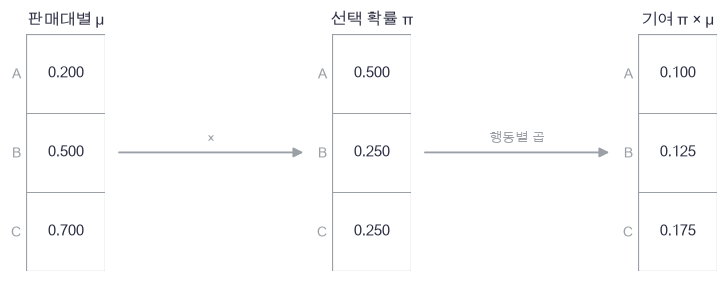

In [3]:
plot_reward_expectation(true_means, example_policy, reward_contributions)

🔍 **확인** · 선택 빈도 π와 판매 성공률 μ를 같은 것으로 읽지 않습니다. 최댓값 행동을 모르므로 학습이 필요합니다. 환경은 선택한 행동에 대해서만 성공·실패를 돌려줍니다.

In [4]:
def expected_reward(policy, means):
    """행동 확률 π:(A,)와 참 평균 μ:(A,)의 내적. → 한 번 선택의 기대 보상."""
    return float(np.sum(policy * means))

In [5]:
np.testing.assert_allclose(expected_reward(example_policy, true_means), 0.4)  # 검산: 0.5×0.2+0.25×0.5+0.25×0.7
np.testing.assert_allclose(expected_reward(np.array([0.0, 0.0, 1.0]), true_means), 0.7)  # 검산: 최적 행동만 고른 정확한 기대값
np.testing.assert_allclose(example_policy.sum(), 1.0)  # 검산: 정책의 확률 합=1
print('정확한 기대 보상의 손계산·반복문·벡터화 통과')

정확한 기대 보상의 손계산·반복문·벡터화 통과


### ✏️ 연습 1 · 정책의 기대 보상

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

행동별 두 확률 배열을 곱해 더하세요.

In [6]:
def exercise_value(policy, means):
    """정책의 기대 보상의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return value

In [7]:
def check_value(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([0.25,0.75]),np.array([0.2,0.6])),0.5)  # 검산: .05+.45=.5
    print('정책 기대값 통과')

run_check(check_value,exercise_value,hint='정책 확률과 보상 평균의 내적입니다.')

☐ exercise_value: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정책 확률과 보상 평균의 내적입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = np.sum(policy * means)
```

</details>

## 🔑 2. 선택한 행동의 표본평균만 갱신합니다

**이 절에서 가져갈 것:** 새 보상 하나를 받으면 해당 행동의 횟수를 늘린 뒤 $1/N_a$로 평균을 고칩니다.

판매대 A에서 차례로 1·0·1·1을 관측했습니다. 이전 보상을 모두 저장하지 않아도 현재 평균과 횟수만으로 같은 평균을 만들 수 있습니다.

$$Q_n=\frac1n\sum_{i=1}^nR_i
=Q_{n-1}+\frac1n(R_n-Q_{n-1}).$$

n은 전체 시간 t가 아니라 **그 행동을 고른 횟수**입니다. `(Q,N)`은 각각 `(A,)`이고 한 칸만 바뀝니다. n=0에서 평균은 정의되지 않아 초기 Q=0을 약속합니다. 첫 보상에서는 n=1이므로 초기값을 완전히 덮어씁니다.

> **용어** · **행동 가치 추정 Q**는 지금까지 받은 보상의 평균입니다. 참 평균 μ와 일반적으로 다릅니다. **점진 갱신(incremental update)**은 이전 요약값과 새 관측만으로 값을 수정하는 방식입니다.

> **코드** · `np.cumsum`은 앞에서부터 누적합을 만듭니다. `np.arange(1,5)`는 1·2·3·4입니다. `np.column_stack`은 두 배열을 열로 붙입니다. `values[action]`은 선택한 칸 하나입니다.

In [8]:
small_rewards = np.array([1.0, 0.0, 1.0, 1.0])
small_averages = np.cumsum(small_rewards) / np.arange(1, 5)
small_values = np.zeros(3)
small_counts = np.zeros(3, dtype=int)
for reward in small_rewards:
    small_counts[0] += 1
    small_values[0] += (reward - small_values[0]) / small_counts[0]
small_table = np.column_stack([small_values, small_counts])

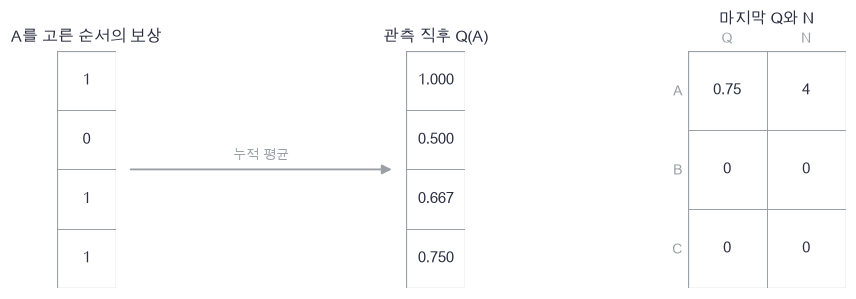

In [9]:
plot_average_update(small_rewards, small_averages, small_table)

🔍 **확인** · A의 마지막 추정은 0.75이지만 아직 B·C는 관측하지 않았습니다. Q=0인 칸은 성공률이 0이라는 결론이 아니라 초기값입니다. 이후 실제 실험에서는 모든 행동을 한 번씩 관측한 뒤 정책을 적용합니다.

In [10]:
def update_average(values, counts, action, reward):
    """선택한 행동만 N←N+1, Q←Q+(R−Q)/N으로 제자리 갱신합니다."""
    counts[action] += 1
    values[action] += (reward - values[action]) / counts[action]

In [11]:
check_values = np.array([9.0, -4.0, 2.0])
check_counts = np.zeros(3, dtype=int)
for reward in [1.0, 0.0, 1.0, 1.0]:
    update_average(check_values, check_counts, 0, reward)
np.testing.assert_allclose(check_values, [0.75, -4.0, 2.0])  # 검산: 선택한 행동의 전체 표본평균과 미선택 값 보존
np.testing.assert_array_equal(check_counts, [4, 0, 0])  # 검산: 행동별 횟수만 증가
print('초기값 제거·표본평균·미선택 행동 보존 통과')

초기값 제거·표본평균·미선택 행동 보존 통과


### ✏️ 연습 2 · 행동별 관측 횟수로 나눕니다

새 보상 관측 후의 횟수 n을 받았습니다. 평균 한 칸을 갱신하세요.

In [12]:
def exercise_average(old, reward, n):
    """행동별 관측 횟수로 나눕니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return updated

In [13]:
def check_average(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(0.5,1.0,3),2.0/3.0)  # 검산: 기존 합1에 새1을 더한 뒤3으로 나눔
    np.testing.assert_allclose(fn(7.0,0.0,1),0.0)  # 검산: 첫 보상이 초기 추정값을 덮어씀
    print('점진 평균 통과')

run_check(check_average,exercise_average,hint='n은 전체 선택 횟수가 아니라 그 행동의 새 횟수입니다.')

☐ exercise_average: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: n은 전체 선택 횟수가 아니라 그 행동의 새 횟수입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
updated = old + (reward - old) / n
```

</details>

## 🔑 3. 동률까지 포함한 ε-greedy 확률을 씁니다

**이 절에서 가져갈 것:** 최대 Q의 동률을 균등 분할하고, 탐색 확률 ε를 모든 행동에 나누어 더합니다.

지금 B와 C의 추정값이 같습니다. `argmax`의 첫 칸만 고르면 행동 번호에 따른 편향이 생깁니다. 여기서는 동률 행동을 똑같은 확률로 고릅니다.

$$g_a=\frac{\mathbf1[Q_a=\max_bQ_b]}{\sum_b\mathbf1[Q_b=\max_jQ_j]},\qquad
\pi_a=(1-\epsilon)g_a+\epsilon/A.$$

ε=0은 현재 최대 추정값만, ε=1은 모든 행동을 균등하게 고릅니다. **탐색에서도 최대 행동을 고를 수 있습니다.** Q=(0.2,0.5,0.5), ε=0.3이면 π=(0.1,0.45,0.45)입니다.

> **용어**
>
> - **greedy**: 현재 가장 큰 추정값의 행동을 고르는 규칙입니다. 참 최적 행동이라는 뜻은 아닙니다.
> - **탐색(exploration)**: 정보를 더 얻기 위해 현재 최대 추정값 이외의 행동도 고르는 것입니다.
> - **ε-greedy**: 확률 1−ε로 greedy, 확률 ε로 전체 행동 중 균등하게 고르는 혼합 규칙입니다.
>
> **코드** · `(Q == Q.max()).astype(float)`는 최댓값 칸을 1, 나머지를 0으로 바꿉니다. 여기서는 계산된 값의 정확한 동률을 사용합니다. `np.stack`은 같은 크기 배열을 행으로 쌓습니다.

In [14]:
tie_values = np.array([0.2, 0.5, 0.5])
tie_greedy = np.array([0.0, 0.5, 0.5])
example_epsilons = [0.0, 0.3, 1.0]
policy_rows = []
for epsilon in example_epsilons:
    policy_rows.append((1 - epsilon) * tie_greedy + epsilon / 3)
policy_rows = np.stack(policy_rows)

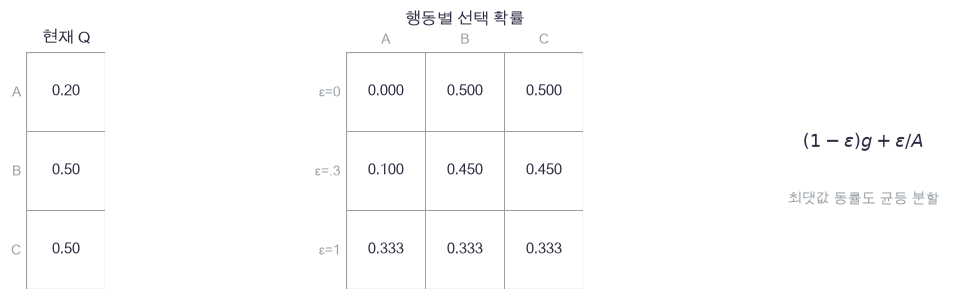

In [15]:
plot_epsilon_policy(tie_values, policy_rows, ['ε=0','ε=.3','ε=1'])

🔍 **확인** · B·C가 각각 0.45이고 A가 0.1입니다. 남은 0.3을 **비최대 행동에게만** 나누지 않습니다. 아래 범주 추출은 균일 난수 u를 누적확률 구간에 넣어 실제 행동 하나를 반환합니다.

> **코드** · `np.searchsorted(cumulative,u,side='right')`는 u가 들어갈 누적확률 구간 번호입니다. 정확한 경계에서는 다음 구간으로 갑니다. u는 0 이상 1 미만이며, 마지막 `min`은 부동소수점 끝자리 오차만 보호합니다.

In [16]:
def epsilon_policy(values, epsilon):
    """최댓값 동률을 균등 분할한 ε-greedy. Q:(A,) → 합이 1인 π:(A,)."""
    greedy = (values == values.max()).astype(float)
    greedy = greedy / greedy.sum()
    return (1.0 - epsilon) * greedy + epsilon / len(values)

In [17]:
def sample_action(policy, uniform):
    """0≤u<1인 고정 난수로 범주를 고릅니다. 누적확률 구간 경계는 오른쪽에 포함합니다."""
    return min(int(np.searchsorted(np.cumsum(policy), uniform, side='right')), len(policy) - 1)

In [18]:
# 쓰는 것: tie_values (위 절의 정의·실행 셀)
np.testing.assert_allclose(epsilon_policy(tie_values,0.3),[0.1,0.45,0.45])  # 검산: 동률과 전체 균등 탐색
np.testing.assert_allclose(epsilon_policy(np.zeros(4),0.2),np.full(4,0.25))  # 검산: 모두 동률이면 균등
np.testing.assert_allclose(epsilon_policy(tie_values,1.0),np.full(3,1/3))  # 검산: ε=1이면 균등
assert sample_action(np.array([0.1,0.45,0.45]),0.05)==0, '첫 구간은 행동0이어야 합니다'
assert sample_action(np.array([0.1,0.45,0.45]),0.1)==1, '정확한 경계는 다음 구간이어야 합니다'
assert sample_action(np.array([0.1,0.45,0.45]),0.99)==2, '마지막 구간은 행동2여야 합니다'
print('동률·ε 양끝·고정 난수의 범주 추출 통과')

동률·ε 양끝·고정 난수의 범주 추출 통과


### ✏️ 연습 3 · 동률을 균등 분할합니다

greedy mask를 확률로 만든 뒤 전체 균등 탐색과 섞으세요.

In [19]:
def exercise_epsilon(values, epsilon):
    """동률을 균등 분할합니다의 핵심 식을 완성합니다."""
    greedy = (values == values.max()).astype(float)
    raise NotImplementedError
    return policy

In [20]:
def check_epsilon(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([2.0,2.0,0.0]),0.3),[0.45,0.45,0.1])  # 검산: 최대 둘의 동률+.1 탐색
    print('동률 epsilon 정책 통과')

run_check(check_epsilon,exercise_epsilon,hint='탐색은 모든 행동에 epsilon/A입니다.')

☐ exercise_epsilon: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 탐색은 모든 행동에 epsilon/A입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
greedy = greedy / greedy.sum()
policy = (1.0 - epsilon) * greedy + epsilon / len(values)
```

</details>

## 🔑 4. 관측 보상과 pseudo-regret를 분리합니다

**이 절에서 가져갈 것:** 알고 있는 μ로 계산하는 기회 손실과 실제 보상의 흔들림은 같은 경로별 숫자가 아닙니다.

최적 판매대를 골라도 판매가 실패할 수 있고, 나쁜 판매대에서 우연히 성공할 수도 있습니다. 한 번의 보상만으로 행동의 품질을 판단하지 않습니다.

$$\mu_\star=\max_a\mu_a,\quad
\mathcal R_T^{pseudo}=\sum_{t=1}^T(\mu_\star-\mu_{A_t}),\qquad
\mathcal R_T^{realized}=T\mu_\star-\sum_{t=1}^TR_t.$$

pseudo-regret는 선택 행동의 평균 격차를 더하므로 비음수이고 감소하지 않습니다. 실제 보상을 뺀 값은 음수이거나 감소할 수 있습니다. 행동을 정한 과거 기록에 조건부로 새 보상 평균이 μ이므로, **실험의 기대값에서는 두 regret가 같습니다.** 한 경로에서 같다는 뜻은 아닙니다.

> **용어** · **regret**는 최적 기준과 비교한 기회 손실입니다. 이 노트북의 **pseudo-regret**는 알려진 환경 μ를 이용한 진단이며 학습자는 이 값을 행동 선택에 쓰지 않습니다. realized 값은 최적 행동의 기대 누적 보상에서 실제 받은 보상을 뺀 정의입니다.

In [21]:
# 쓰는 것: true_means (위 절의 정의·실행 셀)
regret_actions = np.array([2, 2, 0])
regret_rewards = np.array([1.0, 1.0, 0.0])
regret_steps = np.arange(1, 4)
regret_pseudo = np.cumsum(true_means.max() - true_means[regret_actions])
regret_realized = regret_steps * true_means.max() - np.cumsum(regret_rewards)

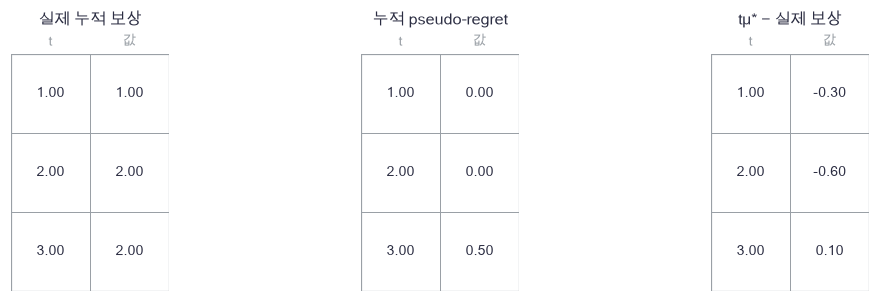

In [22]:
plot_regret_paths(regret_steps, np.cumsum(regret_rewards), regret_pseudo, regret_realized)

🔍 **확인** · 첫 두 번은 최적 행동을 골라 pseudo-regret가 0입니다. 두 번 모두 성공하면 실제 보상 차이는 −0.6입니다. 음수라고 구현 오류가 아닙니다. 여기서는 최적 행동의 가상 보상 표본과 비교하는 별도 정의를 사용하지 않습니다.

In [23]:
def regret_records(means, actions, rewards):
    """누적 pseudo-regret와 실제 보상의 차이. actions,rewards:(T,) → 두 (T,) 배열."""
    pseudo = np.cumsum(means.max() - means[actions])
    realized = np.arange(1, len(actions) + 1) * means.max() - np.cumsum(rewards)
    return pseudo, realized

In [24]:
# 쓰는 것: true_means (위 절의 정의·실행 셀)
checked_pseudo, checked_realized = regret_records(true_means, regret_actions, regret_rewards)
np.testing.assert_allclose(checked_pseudo,[0.0,0.0,0.5])  # 검산: 행동별 평균 격차의 누적합
np.testing.assert_allclose(checked_realized,[-0.3,-0.6,0.1])  # 검산: t×.7−누적 실제 보상
fixed_action = 0
one_step_expected_regret = (1-true_means[fixed_action])*true_means.max() + true_means[fixed_action]*(true_means.max()-1)
np.testing.assert_allclose(one_step_expected_regret,true_means.max()-true_means[fixed_action])  # 검산: 성공·실패 두 상태를 열거한 기대 regret
print('경로별 두 regret와 정확한 한 스텝 기대값 관계 통과')

경로별 두 regret와 정확한 한 스텝 기대값 관계 통과


### ✏️ 연습 4 · 평균 격차를 누적합니다

선택 목록에 해당하는 평균을 모아 누적 pseudo-regret를 구하세요.

In [25]:
def exercise_regret(means, actions):
    """평균 격차를 누적합니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return regret

In [26]:
def check_regret(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([0.2,0.8]),np.array([0,1,0])),[0.6,0.6,1.2])  # 검산: .6+0+.6의 누적합
    print('pseudo-regret 통과')

run_check(check_regret,exercise_regret,hint='참 평균은 평가용이며 정책 입력은 Q입니다.')

☐ exercise_regret: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 참 평균은 평가용이며 정책 입력은 Q입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
regret = np.cumsum(means.max() - means[actions])
```

</details>

## 🔑 5. 같은 예산으로 배우고 정책을 멈춘 뒤 평가합니다

**이 절에서 가져갈 것:** 학습 중 성과와 고정 정책의 새 평가를 나누고, 독립 seed 전체를 실험 단위로 남깁니다.

탐색을 많이 하면 정보를 얻지만 즉시 보상을 놓칠 수 있습니다. 그 효과를 보기 위해 **ε=0·0.05·0.1·0.3, 학습 600회, 독립 실행 48개**를 미리 정합니다. 모든 후보가 첫 세 번에 A·B·C를 한 번씩 관측합니다. 이 공통 초기 탐색도 600회 예산에 포함합니다.

각 실행에서 환경 난수 U:(600,3)와 행동 선택 난수 u:(600,)를 따로 만듭니다. 후보끼리는 같은 표를 공유해 차이를 짝짓지만, 서로 다른 실행은 별도 난수열입니다. 학습자에게 보이는 보상은 선택한 칸 하나뿐입니다.

학습 후 Q를 고정하고 **ε=0의 동률 균등 greedy 정책**을 새로 만듭니다. 그 정책의 정확한 가치는 $J=\pi^\top\mu$입니다. 추가로 학습과 독립인 난수로 1,000번 선택해 표본 보상 평균을 구합니다. 평가에서는 Q·N을 갱신하지 않습니다. 학습 때 탐색이 포함된 정책과 최종 평가 정책은 다릅니다.

> **용어**
>
> - **독립 실행(seed)**: 처음부터 학습을 다시 하는 하나의 실험 단위입니다. 한 실행의 600개 적응적 선택을 600개 독립 학습 실험으로 세지 않습니다.
> - **짝지은 비교**: 같은 실행 번호에서 두 후보의 차이를 먼저 구하는 비교입니다. 공통 난수 때문에 후보의 결과는 서로 독립이 아닙니다.
>
> **코드** · `default_rng(seed)`는 재현 가능한 난수 생성기입니다. `rng.random(shape)`은 `[0,1)` 균일 난수를 만듭니다. `means[actions]`는 행동 번호 목록에 맞춰 평균들을 뽑습니다. `array[:,None]`은 열 축 하나를 추가합니다.

> **코드** · `enumerate(epsilons)`는 설정 번호와 값을 함께 줍니다. `np.diag(U)`는 첫 세 선택 0·1·2의 보상 칸을 읽는 대각 성분입니다. `np.count_nonzero`는 조건이 참인 실행 수를 셉니다.

In [27]:
# 쓰는 것: epsilon_policy, true_means (위 절의 정의·실행 셀)
HORIZON, REPEATS, EVAL_COUNT = 600, 48, 1000
epsilons = [0.0, 0.05, 0.1, 0.3]
experiment_names = ['ε=0','ε=.05','ε=.1','ε=.3']
protocol_rng = np.random.default_rng(51000)
protocol_uniforms = protocol_rng.random((3,3))
protocol_rewards = (np.diag(protocol_uniforms) < true_means).astype(float)
protocol_table = np.column_stack([protocol_rewards,np.ones(3)])
protocol_policy = epsilon_policy(protocol_rewards,0.0)
protocol_settings = np.array([[3],[HORIZON],[REPEATS],[EVAL_COUNT]])

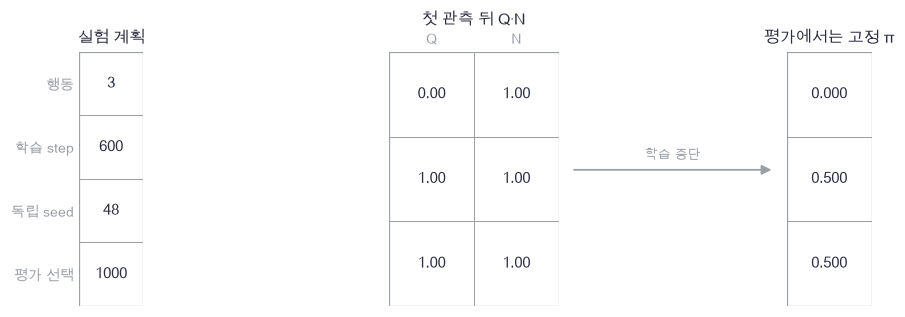

In [28]:
plot_bandit_protocol(protocol_settings, protocol_table, protocol_policy)

🔍 **확인** · 가운데는 첫 세 관측의 모양을 읽기 위한 예입니다. 실제 학습은 아래에서 별도 난수표로 시작합니다. 모든 후보는 동일한 예산을 쓰며 실패한 실행도 제거하지 않습니다. 첫 세 번의 강제 탐색 이후에도 ε=0은 초기 관측에 따라 잘못된 행동에 머무를 수 있습니다.

In [29]:
def run_bandit(means, epsilon, reward_uniforms, action_uniforms):
    """처음 A번은 한 번씩 관측 후 ε-greedy로 실제 학습. 보상 표:(T,A), 선택 난수:(T,)."""
    # 쓰는 것: epsilon_policy, sample_action, update_average (위 절의 정의·실행 셀)
    # 1. learner는 참 평균 대신 선택한 행동의 보상만 받습니다.
    actions_count = len(means)
    horizon = len(action_uniforms)
    values = np.zeros(actions_count)
    counts = np.zeros(actions_count, dtype=int)
    actions = np.zeros(horizon, dtype=int)
    rewards = np.zeros(horizon)
    # 2. 잠재 보상 표의 선택한 칸 하나만 읽고 갱신합니다.
    for step in range(horizon):
        if step < actions_count:
            action = step
        else:
            policy = epsilon_policy(values, epsilon)
            action = sample_action(policy, action_uniforms[step])
        reward = float(reward_uniforms[step, action] < means[action])
        update_average(values, counts, action, reward)
        actions[step] = action
        rewards[step] = reward
    return values, counts, actions, rewards

In [30]:
def evaluate_bandit(policy, means, action_uniforms, reward_uniforms):
    """학습을 멈춘 π의 독립 평가 보상. 두 난수 벡터:(M,) → 보상:(M,)."""
    # 쓰는 것: sample_action (위 절의 정의·실행 셀)
    rewards = np.zeros(len(action_uniforms))
    for step in range(len(rewards)):
        action = sample_action(policy, action_uniforms[step])
        rewards[step] = float(reward_uniforms[step] < means[action])
    return rewards

In [31]:
probe_reward_u = np.array([[0.9,0.9],[0.9,0.1],[0.1,0.1],[0.1,0.1]])
probe_action_u = np.full(4,0.5)
probe_means = np.array([0.2,0.8])
probe_q,probe_n,probe_a,probe_r = run_bandit(probe_means,0.0,probe_reward_u,probe_action_u)
np.testing.assert_array_equal(probe_a,[0,1,1,1])  # 검산: 첫 두 행동 관측 뒤 성공한 행동1만 선택
np.testing.assert_array_equal(probe_n,[1,3])  # 검산: 선택 횟수의 보존
np.testing.assert_allclose(probe_q,[0.0,1.0])  # 검산: 선택한 보상만 표본평균에 반영
print('고정 난수의 실제 학습 경로·관측 분모 검산 통과')

고정 난수의 실제 학습 경로·관측 분모 검산 통과


In [32]:
# 쓰는 것: EVAL_COUNT, HORIZON, REPEATS, epsilon_policy, epsilons, expected_reward, regret_records, true_means (위 절의 정의·실행 셀)
training_rewards = np.zeros((4,REPEATS,HORIZON))
pseudo_regrets = np.zeros_like(training_rewards)
final_values = np.zeros((4,REPEATS,3))
exact_evaluation = np.zeros((4,REPEATS))
sampled_evaluation = np.zeros_like(exact_evaluation)
for repeat in range(REPEATS):
    reward_u = np.random.default_rng(51000+repeat).random((HORIZON,3))
    action_u = np.random.default_rng(52000+repeat).random(HORIZON)
    eval_action_u = np.random.default_rng(53000+repeat).random(EVAL_COUNT)
    eval_reward_u = np.random.default_rng(54000+repeat).random(EVAL_COUNT)
    for setting,epsilon in enumerate(epsilons):
        values,counts,actions,rewards = run_bandit(true_means,epsilon,reward_u,action_u)
        pseudo,realized = regret_records(true_means,actions,rewards)
        frozen_policy = epsilon_policy(values,0.0)
        eval_rewards = evaluate_bandit(frozen_policy,true_means,eval_action_u,eval_reward_u)
        training_rewards[setting,repeat] = rewards
        pseudo_regrets[setting,repeat] = pseudo
        final_values[setting,repeat] = values
        exact_evaluation[setting,repeat] = expected_reward(frozen_policy,true_means)
        sampled_evaluation[setting,repeat] = eval_rewards.mean()
print('학습 완료: 4설정 × 48실행 × 600회 · 평가 1,000회/정책')

학습 완료: 4설정 × 48실행 × 600회 · 평가 1,000회/정책


🔍 **학습 기록** · 누적 보상을 시간으로 나누고 seed 축을 평균합니다. pseudo-regret 띠는 각 시점의 **48개 독립 실행 평균의 SE**입니다. 시간별 점들은 서로 관련되어 있으므로 띠를 전체 곡선의 동시 신뢰구간으로 읽지 않습니다. 한 경로의 성공을 보장하는 선도 아닙니다.

> **코드** · `enumerate(epsilons)`는 설정 번호와 값을 함께 줍니다. `std(axis=1,ddof=1)/sqrt(REPEATS)`는 독립 학습 실행 축의 평균 표준오차입니다. `axis=2`는 시간 축입니다.

In [33]:
# 쓰는 것: HORIZON, REPEATS (위 절의 정의·실행 셀)
learning_steps = np.arange(1,HORIZON+1)
cumulative_average_rewards = np.cumsum(training_rewards,axis=2) / learning_steps
learning_reward_mean = cumulative_average_rewards.mean(axis=1)
learning_regret_mean = pseudo_regrets.mean(axis=1)
learning_regret_se = pseudo_regrets.std(axis=1,ddof=1) / np.sqrt(REPEATS)

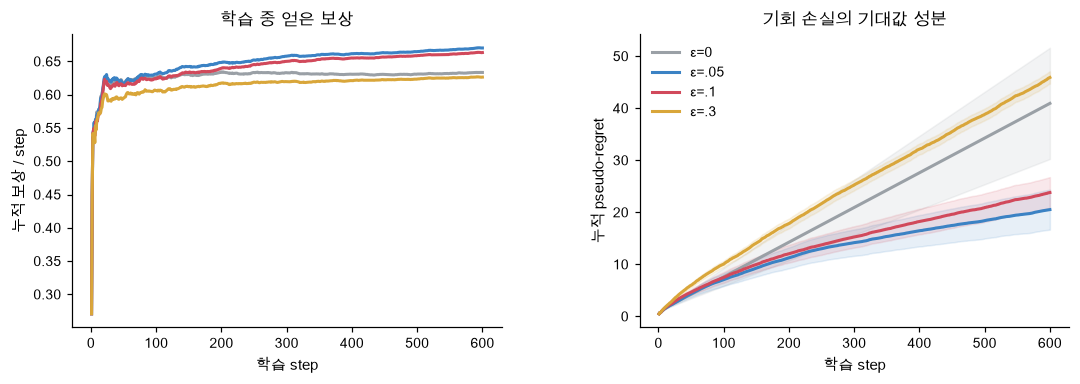

In [34]:
plot_bandit_learning(learning_steps, learning_reward_mean, learning_regret_mean, learning_regret_se, experiment_names)

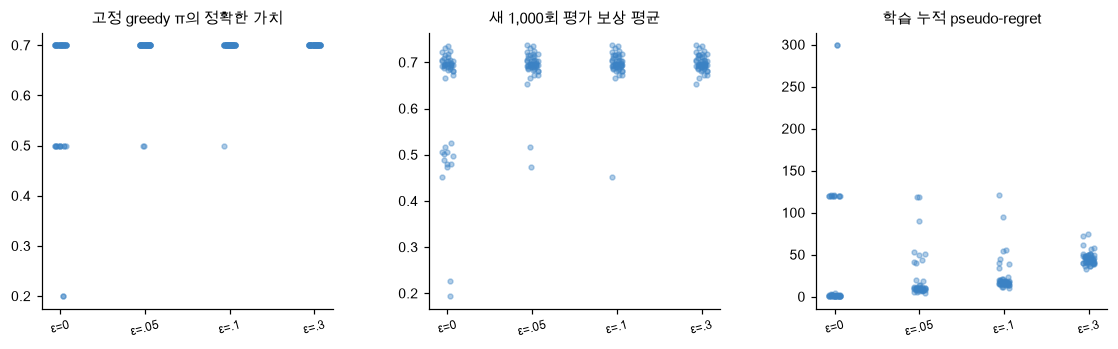

In [35]:
plot_bandit_evaluation(experiment_names, exact_evaluation, sampled_evaluation, pseudo_regrets[:,:,-1])

🔍 **고정 정책 평가** · 점 하나가 학습 실행 하나입니다. 왼쪽은 이미 알고 있는 환경 μ로 정확히 계산한 가치이며 평가 표본 오차가 없습니다. 가운데는 새 1,000번 보상의 평균이라 흔들립니다. 마지막은 그 정책을 배우는 동안 쓴 기회 비용입니다. 최종 정책 가치가 같아도 학습 중 regret는 다를 수 있습니다.

모든 ε의 순위는 이 μ·예산·초기 탐색 규칙에서 관측한 결과입니다. ε가 크면 항상 좋아진다거나 600번이면 반드시 최적 행동을 찾는다고 주장하지 않습니다. 고정 ε의 탐색 비용은 좋은 행동을 알아도 계속 남으므로, 평가를 greedy로 바꿨다는 약속도 함께 읽습니다.

In [36]:
# 쓰는 것: REPEATS, exact_evaluation, experiment_names, pseudo_regrets, training_rewards, true_means (위 절의 정의·실행 셀)
for setting,name in enumerate(experiment_names):
    values = exact_evaluation[setting]
    failures = np.count_nonzero(values < true_means.max()-1e-12)
    print(name,'최종 정확한 가치 평균/SD:',round(values.mean(),4),round(values.std(ddof=1),4),'최적 미달 실행:',failures,'/',REPEATS)
    print('  학습 평균 보상:',round(training_rewards[setting].mean(),4),'누적 pseudo-regret:',round(pseudo_regrets[setting,:,-1].mean(),2))
paired_difference = exact_evaluation[2]-exact_evaluation[0]
print('ε=.1 − ε=0, 정확한 평가 차이 평균/SE:',paired_difference.mean(),paired_difference.std(ddof=1)/np.sqrt(REPEATS))
assert np.all(pseudo_regrets>=-1e-12), 'pseudo-regret는 비음수이어야 합니다'
assert np.isfinite(exact_evaluation).all(), '모든 실행의 평가값은 유한해야 합니다'
print('실험 배열의 정의·유한값 검사 통과 · 성능 우열은 assert하지 않습니다')

ε=0 최종 정확한 가치 평균/SD: 0.6333 0.1243 최적 미달 실행: 13 / 48
  학습 평균 보상: 0.6333 누적 pseudo-regret: 40.93
ε=.05 최종 정확한 가치 평균/SD: 0.6917 0.0404 최적 미달 실행: 2 / 48
  학습 평균 보상: 0.6701 누적 pseudo-regret: 20.52
ε=.1 최종 정확한 가치 평균/SD: 0.6958 0.0289 최적 미달 실행: 1 / 48
  학습 평균 보상: 0.6632 누적 pseudo-regret: 23.8
ε=.3 최종 정확한 가치 평균/SD: 0.7 0.0 최적 미달 실행: 0 / 48
  학습 평균 보상: 0.6264 누적 pseudo-regret: 45.91
ε=.1 − ε=0, 정확한 평가 차이 평균/SE: 0.06249999999999998 0.017771450927966077
실험 배열의 정의·유한값 검사 통과 · 성능 우열은 assert하지 않습니다


### ✏️ 연습 5 · 같은 seed끼리 차이를 냅니다

두 후보의 seed별 정확한 정책 가치로 평균 차이와 그 SE를 구하세요.

In [37]:
def exercise_paired(candidate_a, candidate_b):
    """같은 seed끼리 차이를 냅니다의 핵심 식을 완성합니다."""
    difference = candidate_b - candidate_a
    raise NotImplementedError
    return mean, se

In [38]:
def check_paired(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([0.,1.,2.]),np.array([1.,3.,5.])),[2.,1/np.sqrt(3)])  # 검산: 차이 [1,2,3]의 평균·SE
    print('짝지은 실행 차이 통과')

run_check(check_paired,exercise_paired,hint='후보를 독립이라고 놓기 전에 같은 실행끼리 빼세요.')

☐ exercise_paired: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 후보를 독립이라고 놓기 전에 같은 실행끼리 빼세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mean = difference.mean()
se = difference.std(ddof=1) / np.sqrt(len(difference))
```

</details>

## ✏️ 전체 연결 연습 A–D

행동 축·첫 관측·탐색 비중·평가 오차를 다른 작은 배열에서 확인합니다.

### ✏️ 연습 A · 여러 정책을 한 번에 평가합니다

policies의 각 행은 정책 하나입니다.

In [39]:
def exercise_batch_value(policies, means):
    """여러 정책을 한 번에 평가합니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return values

In [40]:
def check_batch_value(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.eye(2),np.array([0.2,0.8])),[0.2,0.8])  # 검산: 각 행동만 선택하는 두 정책
    print('정책 행별 내적 통과')

run_check(check_batch_value,exercise_batch_value,hint='정책 행과 행동 열을 유지한 행렬곱입니다.')

☐ exercise_batch_value: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정책 행과 행동 열을 유지한 행렬곱입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
values = policies @ means
```

</details>

### ✏️ 연습 B · 표본 합에서 평균을 읽습니다

관측 횟수가 0인 칸의 초기 Q는 0으로 둡니다.

In [41]:
def exercise_counts(totals, counts):
    """표본 합에서 평균을 읽습니다의 핵심 식을 완성합니다."""
    values = np.zeros_like(totals, dtype=float)
    observed = counts > 0
    raise NotImplementedError
    return values

In [42]:
def check_counts(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([3.,0.,1.]),np.array([4,0,2])),[0.75,0.,0.5])  # 검산: 관측된 행동의 분모만 사용
    print('미관측 칸과 표본평균 구별 통과')

run_check(check_counts,exercise_counts,hint='0으로 나누는 칸을 제외합니다.')

☐ exercise_counts: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 0으로 나누는 칸을 제외합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
values[observed] = totals[observed] / counts[observed]
```

</details>

### ✏️ 연습 C · 탐색의 즉시 기대 비용

최적 행동 하나의 확률이 1−ε+ε/A일 때, ε-greedy의 정확한 기대 보상을 구하세요.

In [43]:
def exercise_known_best(means, epsilon):
    """탐색의 즉시 기대 비용의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return value

In [44]:
def check_known_best(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([0.2,0.8]),0.5),0.65)  # 검산: .5×.8+.5×.5
    print('알려진 최적 행동에서 탐색 비용 통과')

run_check(check_known_best,exercise_known_best,hint='greedy 기대값과 균등 기대값을 섞습니다.')

☐ exercise_known_best: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: greedy 기대값과 균등 기대값을 섞습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = (1.0 - epsilon) * means.max() + epsilon * means.mean()
```

</details>

### ✏️ 연습 D · 고정 정책의 새 보상 SE

학습이 끝난 정책으로 독립 평가한 보상만 받았습니다.

In [45]:
def exercise_eval_se(rewards):
    """고정 정책의 새 보상 SE의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return se

In [46]:
def check_eval_se(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([0.,1.])),0.5)  # 검산: 표본 SD=sqrt(.5), sqrt(2)로 나눔
    print('고정 정책 평가의 표준오차 통과')

run_check(check_eval_se,exercise_eval_se,hint='적응적으로 정책을 갱신하는 학습 보상에 같은 iid 해석을 붙이지 않습니다.')

☐ exercise_eval_se: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 적응적으로 정책을 갱신하는 학습 보상에 같은 iid 해석을 붙이지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
se = rewards.std(ddof=1) / np.sqrt(len(rewards))
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

1. **설명:** μ·Q·π의 차이와 선택하지 않은 보상을 학습자가 볼 수 없는 이유를 설명할 수 있나요?
2. **수식:** 점진 표본평균, 동률 ε-greedy, 경로별 두 regret와 기대값 관계를 다시 쓸 수 있나요?
3. **구현:** 행동별 N의 증가 시점과 고정 정책 평가에서 갱신이 없는 것을 찾아 확인할 수 있나요?
4. **변형 검산:** 행동 5개·동률 최적 행동·ε=0/1로 바꿔 확률 합과 평균 갱신을 다시 검사할 수 있나요? 비정상 환경에서는 표본평균이 오래된 관측을 계속 포함한다는 점도 설명해 보세요.

### 📎 원자료와 다음 연결

[Sutton·Barto, Reinforcement Learning: An Introduction, 2판](https://reinforcementlearning.pubpub.org/)의 2장이 행동 가치·표본평균·ε-greedy의 배경입니다. 여기서는 정상 Bernoulli 환경과 동률 균등 처리, 공통 초기 탐색을 명시한 작은 실험으로 재구성했습니다.

52번에서는 행동이 다음 상태까지 바꾸는 MDP로 확장합니다. 27번의 기대값과 SE를 복습하면 이 단원의 **보상 표본**과 **독립 학습 실행**을 더 분명하게 구별할 수 있습니다.